In [1]:
import pandas as pd

df = pd.read_csv("stats.csv", encoding="latin1", delimiter=";")

In [2]:
df.columns

Index(['Rk', 'Player', 'Pos', 'Age', 'Tm', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%',
       '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%',
       'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS'],
      dtype='object')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 30 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Rk      217 non-null    int64  
 1   Player  217 non-null    object 
 2   Pos     217 non-null    object 
 3   Age     217 non-null    int64  
 4   Tm      217 non-null    object 
 5   G       217 non-null    int64  
 6   GS      217 non-null    int64  
 7   MP      217 non-null    float64
 8   FG      217 non-null    float64
 9   FGA     217 non-null    float64
 10  FG%     217 non-null    float64
 11  3P      217 non-null    float64
 12  3PA     217 non-null    float64
 13  3P%     217 non-null    float64
 14  2P      217 non-null    float64
 15  2PA     217 non-null    float64
 16  2P%     217 non-null    float64
 17  eFG%    217 non-null    float64
 18  FT      217 non-null    float64
 19  FTA     217 non-null    float64
 20  FT%     217 non-null    float64
 21  ORB     217 non-null    float64
 22  DR

In [4]:
df["PTS"].describe()

count    217.000000
mean       8.699078
std        8.375692
min        0.000000
25%        2.000000
50%        6.500000
75%       12.700000
max       34.500000
Name: PTS, dtype: float64

In [5]:
df["Age"].mean()

27.05069124423963

<Axes: xlabel='AST', ylabel='TOV'>

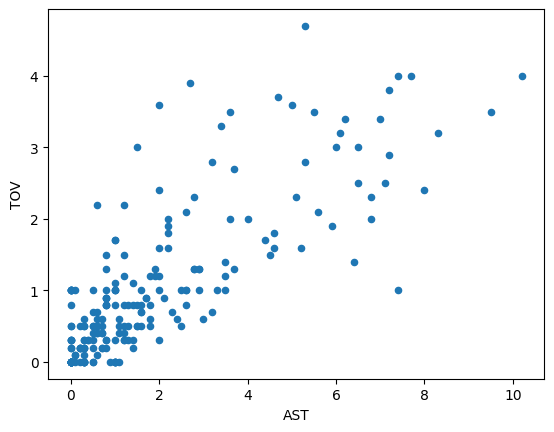

In [6]:
df.plot(kind="scatter",x="AST", y="TOV")

In [7]:
df["AST"].corr(df["TOV"])

0.7995540370064588

In [8]:
df.nlargest(3,"G")[["Player","G", "Tm"]]

,Player,G,Tm
0,Bam Adebayo,23,MIA
121,Kyle Lowry,23,MIA
124,Caleb Martin,23,MIA


In [9]:
df.groupby("Tm")["G"].max().sort_values(ascending=False)

Tm
MIA    23
BOS    20
DEN    20
LAL    16
GSW    13
NYK    11
PHI    11
PHO    11
SAC     7
ATL     6
MEM     6
CLE     5
LAC     5
MIL     5
MIN     5
BRK     4
Name: G, dtype: int64

In [10]:
df[(df["PTS"] > 20) & (df["AST"] > 5)][["Player","AST","PTS"]]

,Player,AST,PTS
6,Giannis Antetokounmpo,5.3,23.3
20,Devin Booker,7.2,33.7
29,Jalen Brunson,5.6,27.8
31,Jimmy Butler,5.9,26.9
47,Stephen Curry,6.1,30.5
56,Kevin Durant,5.5,29.0
57,Anthony Edwards,5.2,31.6
61,De'Aaron Fox,7.7,27.4
74,James Harden,8.3,20.3
95,LeBron James,6.5,24.5


In [11]:
df.query("PTS > 20 and AST > 5")[["Player", "AST", "PTS"]].sort_values(by="AST",ascending=False)

,Player,AST,PTS
213,Trae Young,10.2,29.2
99,Nikola Joki?,9.5,30.0
74,James Harden,8.3,20.3
61,De'Aaron Fox,7.7,27.4
207,Russell Westbrook,7.4,23.6
20,Devin Booker,7.2,33.7
137,Donovan Mitchell,7.2,23.2
145,Jamal Murray,7.1,26.1
142,Ja Morant,7.0,24.6
144,Dejounte Murray,6.8,23.0


In [12]:
df["Rating"] = df["PTS"] + df["AST"] + df["TRB"] + df["BLK"].apply(lambda x: x * 2) + df["STL"].apply(lambda x: x * 2)

In [13]:
df["Eff"] = df["Rating"] * df["eFG%"]

In [14]:
df.nlargest(5,"Rating")[["Player","Eff","Rating"]]

,Player,Eff,Rating
99,Nikola Joki?,33.8052,57.2
113,Kawhi Leonard,31.9280,52.0
20,Devin Booker,32.9043,50.7
57,Anthony Edwards,27.0712,49.4
48,Anthony Davis,25.5990,48.3


<Axes: ylabel='Frequency'>

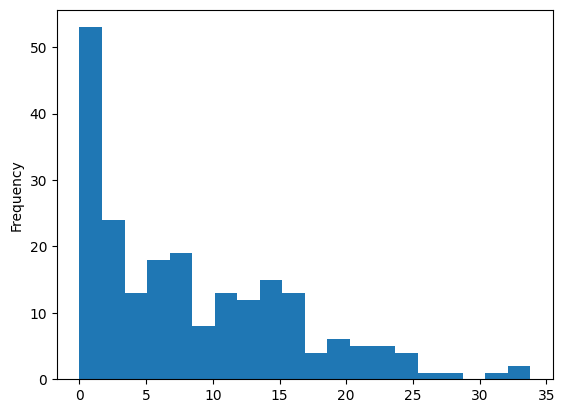

In [15]:
df["Eff"].plot(kind='hist', x="Eff", bins=20)